# EV Charging (Palo Alto) – Minimal Data Cleaning & Exploration
Quick first look at `data/EVChargingStationUsage.csv`. Each row is one charging event.
Sections: 1. Load · 2. Clean · 3. Explore

## 1. Load

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data/EVChargingStationUsage.csv', encoding='utf-8-sig', low_memory=False)
print(df.shape)
df.head(3)

(259415, 33)


,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/29/2011 20:17,PDT,7/29/2011 23:20,PDT,7/29/2011 23:20,3:03:32,1:54:03,...,-122.160309,USD,0.0,Plug Out at Vehicle,3,95124.0,3284,NaN,NaN,NaN
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 0:00,PDT,7/30/2011 0:02,PDT,7/30/2011 0:02,0:02:06,0:01:54,...,-122.160309,USD,0.0,Customer,4,94301.0,4169,NaN,NaN,NaN
2,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 8:16,PDT,7/30/2011 12:34,PDT,7/30/2011 12:34,4:17:32,4:17:28,...,-122.160309,USD,0.0,Plug Out at Vehicle,5,94301.0,4169,NaN,NaN,NaN


In [2]:
# show all of the missing values and number of unique values per column
pd.DataFrame({'missing': df.isna().sum(), 'unique': df.nunique()})

,missing,unique
Station Name,0,47
MAC Address,0,83
Org Name,0,2
Start Date,0,244798
Start Time Zone,0,3
End Date,0,244159
End Time Zone,0,3
Transaction Date (Pacific Time),209,240905
Total Duration (hh:mm:ss),0,31025
Charging Time (hh:mm:ss),0,22473


## 2. Clean
- Drop columns that are constant or mostly empty (`EVSE ID`, `System S/N`, `Model Number`, `County`, `Country`, `City`, ...)
- Parse dates and `hh:mm:ss` durations
- Remove rows with missing/invalid timestamps, non-positive energy/duration, and duplicates

In [3]:
# drop columsn that are empty or constant or mostly empty
drop_cols = ['EVSE ID', 'System S/N', 'Model Number', 'County', 'Country', 'City',
             'State/Province', 'Org Name', 'Address 1', 'GHG Savings (kg)', 'Gasoline Savings (gallons)']
df = df.drop(columns=drop_cols)

In [4]:
# dates to datetime
for c in ['Start Date', 'End Date', 'Transaction Date (Pacific Time)']:
    df[c] = pd.to_datetime(df[c], format='%m/%d/%Y %H:%M', errors='coerce')

# hh:mm:ss to amount of hours
for c in ['Total Duration (hh:mm:ss)', 'Charging Time (hh:mm:ss)']:
    df[c.split(' (')[0] + ' (h)'] = pd.to_timedelta(df[c], errors='coerce').dt.total_seconds() / 3600
    df = df.drop(columns=c)

# categoricals / ids
df['Station Name'] = df['Station Name'].str.replace('# ', '#', regex=False)   # 'BRYANT # 1' vs 'BRYANT #1'
df['User ID'] = df['User ID'].astype('string')
for c in ['Station Name', 'Port Type', 'Plug Type', 'Ended By', 'Currency']:
    df[c] = df[c].astype('category')

n0 = len(df)
df = df.drop_duplicates()
df = df.dropna(subset=['Start Date', 'End Date', 'Total Duration (h)', 'Charging Time (h)'])
df = df[(df['Energy (kWh)'] > 0) & (df['Total Duration (h)'] > 0)]
df = df[df['Charging Time (h)'] <= df['Total Duration (h)'] + 1/60]   # charging can't exceed plugged-in time
print(f'removed {n0 - len(df):,} rows, {len(df):,} left')
print('User ID missing:', df['User ID'].isna().sum())
df.dtypes

removed 84 rows, 259,331 left
User ID missing: 7672


Station Name                             category
MAC Address                                   str
Start Date                         datetime64[us]
Start Time Zone                               str
End Date                           datetime64[us]
End Time Zone                                 str
Transaction Date (Pacific Time)    datetime64[us]
Energy (kWh)                              float64
Port Type                                category
Port Number                                 int64
Plug Type                                category
Postal Code                                 int64
Latitude                                  float64
Longitude                                 float64
Currency                                 category
Fee                                       float64
Ended By                                 category
Plug In Event Id                            int64
Driver Postal Code                        float64
User ID                                    string


## 3. Explore

In [5]:
df[['Energy (kWh)', 'Total Duration (h)', 'Charging Time (h)', 'Fee']].describe().T

,count,mean,std,min,25%,50%,75%,max
Energy (kWh),259331.0,8.542158,7.178858,0.010000,3.784000,6.868000,11.457296,97.360000
Total Duration (h),259331.0,2.486957,2.212776,0.016667,1.171111,2.089444,3.090278,114.539167
Charging Time (h),259331.0,1.998646,1.381510,0.001667,1.040000,1.816389,2.697222,22.931944
Fee,259331.0,1.096795,1.923983,0.000000,0.000000,0.000000,1.640000,84.560000


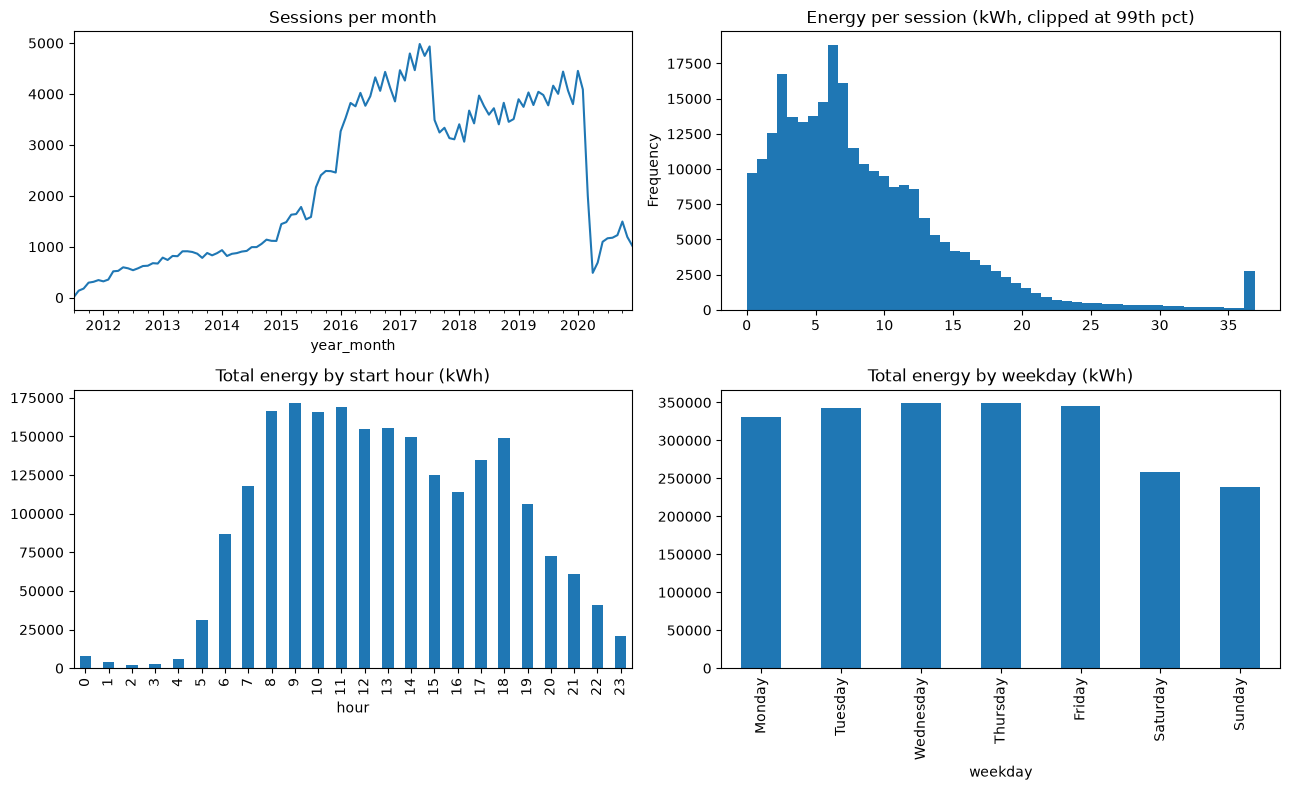

In [6]:
# helper time features, then look at demand over time
df['year_month'] = df['Start Date'].dt.to_period('M')
df['hour'] = df['Start Date'].dt.hour
df['weekday'] = df['Start Date'].dt.day_name()
df['hoarding_h'] = df['Total Duration (h)'] - df['Charging Time (h)']   # plugged in but not charging

fig, ax = plt.subplots(2, 2, figsize=(13, 8))

df.groupby('year_month').size().plot(ax=ax[0, 0], title='Sessions per month')

df['Energy (kWh)'].clip(upper=df['Energy (kWh)'].quantile(0.99)).plot.hist(
    bins=50, ax=ax[0, 1], title='Energy per session (kWh, clipped at 99th pct)')

df.groupby('hour')['Energy (kWh)'].sum().plot.bar(ax=ax[1, 0], title='Total energy by start hour (kWh)')

order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df.groupby('weekday')['Energy (kWh)'].sum().reindex(order).plot.bar(ax=ax[1, 1], title='Total energy by weekday (kWh)')

plt.tight_layout(); plt.show()

In [7]:
# Stations and users
print('Stations:', df['Station Name'].nunique(), '| Users:', df['User ID'].nunique())
df.groupby('Station Name', observed=True)['Energy (kWh)'].agg(['count', 'sum']).sort_values('sum', ascending=False).head(10)

Stations: 46 | Users: 21440


,count,sum
Station Name,,
PALO ALTO CA / HAMILTON #2,23713,191578.535606
PALO ALTO CA / WEBSTER #1,14427,139030.772988
PALO ALTO CA / WEBSTER #2,12665,125697.976951
PALO ALTO CA / HAMILTON #1,14884,113676.717588
PALO ALTO CA / HIGH #4,13896,111856.053979
PALO ALTO CA / BRYANT #2,14381,107215.067295
PALO ALTO CA / BRYANT #1,13448,102355.583403
PALO ALTO CA / WEBSTER #3,10479,98527.968563
PALO ALTO CA / HIGH #1,10751,98361.413769


In [8]:
# Sessions per user (heavy-tailed?) and hoarding
sessions_per_user = df.groupby('User ID').size()
print(sessions_per_user.describe())
print(f"\nMedian hoarding time: {df['hoarding_h'].median():.2f} h | share of sessions with >2h idle: {(df['hoarding_h'] > 2).mean():.1%}")
print(df['Ended By'].value_counts().head(5))
print(df['Port Type'].value_counts())

count    21440.000000
mean        11.737826
std         44.806040
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max       1115.000000
dtype: float64

Median hoarding time: 0.01 h | share of sessions with >2h idle: 5.9%
Ended By
Plug Out at Vehicle    210658
Customer                41077
CPS Server               7065
Outlet Unreachable         64
Door Open                  54
Name: count, dtype: int64
Port Type
Level 2    254652
Level 1      4670
Name: count, dtype: int64


## 4. Hourly energy & occupancy per station
Needed for clustering (task 1) and forecasting (task 2). Each session is spread over the hours it overlaps:
- **Energy**: session kWh split evenly over the *charging* window (assumed to start at plug-in and last `Charging Time`)
- **Occupancy**: hours the plug is in use (plug-in to unplug, i.e. including hoarding) – summed over ports, so it can exceed 1 per hour

In [9]:
H = pd.Timedelta(hours=1)

def spread(frame, dur_col):
    """One row per (session, hour touched) with hours of overlap between session window and that clock hour."""
    s = frame['Start Date']
    e = s + pd.to_timedelta(frame[dur_col], unit='h')
    first = s.dt.floor('h')
    n = ((e.dt.ceil('h') - first) / H).astype(int).clip(lower=1)
    rep = frame.index.repeat(n)
    k = pd.Series(1, index=rep).groupby(level=0).cumcount().values
    out = pd.DataFrame({'station': frame.loc[rep, 'Station Name'].values,
                        'hour': first.loc[rep].values + k * H,
                        's': s.loc[rep].values, 'e': e.loc[rep].values,
                        'dur': frame.loc[rep, dur_col].values,
                        'kwh': frame.loc[rep, 'Energy (kWh)'].values})
    lo = out['hour'].where(out['hour'] > out['s'], out['s'])
    hi = (out['hour'] + H).where(out['hour'] + H < out['e'], out['e'])
    out['overlap_h'] = ((hi - lo) / H).clip(lower=0)
    return out

d = df.reset_index(drop=True)
en = spread(d, 'Charging Time (h)')
en['energy'] = en['kwh'] * en['overlap_h'] / en['dur']
occ = spread(d, 'Total Duration (h)')

hourly_energy = en.pivot_table(index='hour', columns='station', values='energy', aggfunc='sum', observed=True)
hourly_occ = occ.pivot_table(index='hour', columns='station', values='overlap_h', aggfunc='sum', observed=True)

# full hourly grid; zeros between a station's first and last activity, NaN outside (station not yet/no longer in operation)
grid = pd.date_range(hourly_occ.index.min(), hourly_occ.index.max(), freq='h')
def fill(x):
    x = x.reindex(grid)
    active = x.notna().cummax() & x[::-1].notna().cummax()[::-1]
    return x.fillna(0).where(active)
hourly_energy = fill(hourly_energy.reindex(columns=hourly_occ.columns)); hourly_occ = fill(hourly_occ)

print(hourly_energy.shape)
print(f"energy conserved: {hourly_energy.sum().sum():,.0f} kWh vs {d['Energy (kWh)'].sum():,.0f} kWh in sessions")
hourly_energy.iloc[:, :3].dropna(how='all').tail()

(82647, 46)
energy conserved: 2,215,246 kWh vs 2,215,246 kWh in sessions


station,PALO ALTO CA / BRYANT #1,PALO ALTO CA / BRYANT #2,PALO ALTO CA / BRYANT #3
2020-12-24 15:00:00,0.000000,NaN,NaN
2020-12-24 16:00:00,0.000000,NaN,NaN
2020-12-24 17:00:00,0.000000,NaN,NaN
2020-12-24 18:00:00,0.163238,NaN,NaN
2020-12-24 19:00:00,1.287762,NaN,NaN


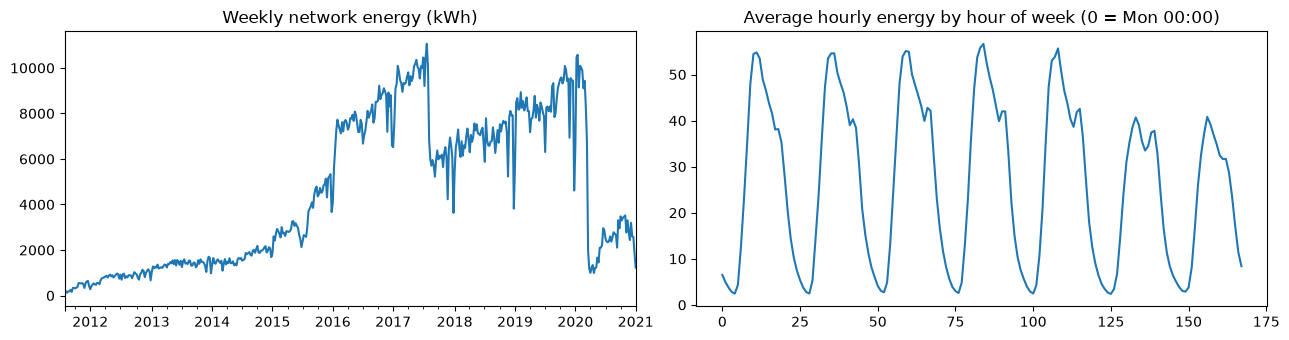

In [10]:
# Total network energy and an average week
total = hourly_energy.sum(axis=1)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
total.resample('W').sum().plot(ax=ax[0], title='Weekly network energy (kWh)')
wk = total.groupby([total.index.day_of_week, total.index.hour]).mean()
wk.plot(ax=ax[1], title='Average hourly energy by hour of week (0 = Mon 00:00)', use_index=False)
plt.tight_layout(); plt.show()

## 5. Chronological 70/30 train/test split (no shuffling)
As the project requires: first 70 % of the time range for training, the rest for testing.

In [11]:
cut = grid[int(len(grid) * 0.7)]
train_energy, test_energy = hourly_energy[hourly_energy.index < cut], hourly_energy[hourly_energy.index >= cut]
train_occ, test_occ = hourly_occ[hourly_occ.index < cut], hourly_occ[hourly_occ.index >= cut]
print(f'train: {train_energy.index.min()} -> {train_energy.index.max()}  ({len(train_energy):,} h)')
print(f'test : {test_energy.index.min()} -> {test_energy.index.max()}  ({len(test_energy):,} h)')

train: 2011-07-29 20:00:00 -> 2018-03-05 07:00:00  (57,852 h)
test : 2018-03-05 08:00:00 -> 2021-01-01 10:00:00  (24,795 h)


## Observations
- Demand grew from ~1k sessions (2011) to ~47k/year in 2016-2019, then dropped in 2020 (likely COVID).
- Energy peaks for sessions starting around 09:00; weekdays use ~340k kWh each vs ~240-260k for Sat/Sun (workplace-like pattern).
- Usage is heavy-tailed across users: median 2 sessions, max >1,000.
- Stations are not all active over the whole period, hence the NaNs outside each station's operating range in the hourly tables.
- Assumptions: charging runs from plug-in for `Charging Time`; energy is spread evenly over that window.
- Next: baseline "average week" forecast (task 2), user-level hourly profiles for clustering (task 1).